# Lab01 · Дополнительное исследование КТиД

## Красное вино: остаточный сахар и спирт. Сравнение с белым

Этот ноутбук дополняет первый спринт; **генератор отложен** до работы инфохимиков.

**Как открыть:** распакуйте проект и откройте этот файл в папке `lab01-site`. CSV находятся в `public/`. Нужны библиотеки из `requirements.txt`; дополнительных пакетов не требуется. Результаты уже сохранены в ячейках. Код помечен для скрытия в поддерживающих это интерфейсах; в marimo-версии на сайте используются закрытые блоки со стрелками.

[Источник](#extra-data) · [Сахар](#extra-sugar) · [Спирт](#extra-alcohol) · [Зависимость](#extra-dependence) · [Сравнение](#extra-comparison) · [Устойчивость](#extra-sensitivity) · [Выводы](#extra-resume)


Исследуем **отдельный файл красного вина** `winequality-red.csv` из коллекции UCI Wine Quality.
В нём 1599 строк и 12 столбцов. Белое вино из первого спринта используется как группа сравнения
(4898 строк). Это два набора образцов из одной коллекции, а не два независимых источника данных.
Источник описывает красные и белые вина Vinho Verde с севера Португалии.

**Вопрос исследования:** как распределены остаточный сахар и спирт у красных вин и повторяется ли
связь между ними, обнаруженная у белых? Выбираем те же единицы и методы, чтобы сравнение было содержательным.
Дополнительный анализ выполняется на исходных измерениях; сторонние разборы этого датасета не использовались.

**План:** источник и подготовка → две случайные величины → EDA каждой → зависимость внутри красного
набора → сравнение с белым → устойчивость к обработке повторов → выводы и критерии.
Генератор и его интерфейс в этот этап не входят.


In [1]:
"""Расчёты дополнительного исследования КТиД. Нужны numpy, pandas, scipy, matplotlib."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


EXTRA_VARS = {
    'residual sugar': ('Остаточный сахар', 'г/л'),
    'alcohol': ('Содержание спирта', '% об.'),
}
EXTRA_COLORS = {'Красное': '#A3333D', 'Белое': '#4F7A45'}


def extra_load(directory):
    root = Path(directory)
    red = pd.read_csv(root / 'winequality-red.csv', sep=';')
    white = pd.read_csv(root / 'winequality-white.csv', sep=';')
    if list(red.columns) != list(white.columns):
        raise ValueError('Схемы исходных таблиц различаются')
    for frame in (red, white):
        if frame[list(EXTRA_VARS)].isna().any().any():
            raise ValueError('В исследуемых величинах есть пропуски')
    return red, white


def extra_holm(pvalues):
    """Поправка Холма с восстановлением исходного порядка гипотез."""
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    adjusted = np.minimum(1., np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1)))
    result = np.empty_like(p)
    result[order] = adjusted
    return result


def extra_describe(frame):
    rows = []
    for col, (label, unit) in EXTRA_VARS.items():
        x = frame[col]
        q1, q3 = x.quantile([.25, .75])
        lo, hi = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
        w, p = stats.shapiro(x)
        rows.append([label, len(x), x.mean(), x.median(), x.std(ddof=1), x.min(), q1,
                     q3, x.max(), x.skew(), x.kurt(), int(((x<lo)|(x>hi)).sum()),
                     lo, hi, w, p])
    return pd.DataFrame(rows, columns=['Величина','n','Среднее','Медиана','Std','Min','Q1','Q3','Max',
                         'Асимметрия','Эксцесс','Выбросов IQR','Нижняя граница IQR','Верхняя граница IQR',
                         'Шапиро W','Шапиро p']).set_index('Величина')


def extra_dependence(frame):
    x, y = frame['residual sugar'], frame['alcohol']
    r, pr = stats.pearsonr(x, y)
    rho, ps = stats.spearmanr(x, y)
    # Округлённые значения на границе квантилей не разделяются произвольно.
    table = pd.crosstab(pd.qcut(x, 4, duplicates='drop'), pd.qcut(y, 4, duplicates='drop'))
    chi, pc, dof, expected = stats.chi2_contingency(table, correction=False)
    v = np.sqrt(chi/(len(frame)*min(table.shape[0]-1, table.shape[1]-1)))
    return {'n':len(frame), 'Пирсон r':r, 'Пирсон p':pr, 'Спирмен ρ':rho,
            'Спирмен p':ps, 'χ²':chi, 'χ² p':pc, 'df':dof, 'V Крамера':v,
            'min ожидаемая частота':expected.min(), 'table':table}


def extra_compare(red, white):
    rows=[]
    for col, (label, unit) in EXTRA_VARS.items():
        a, b = red[col], white[col]
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided', method='asymptotic')
        a12 = u/(len(a)*len(b))
        rows.append([label, len(a), len(b), a.mean(), b.mean(), a.median(), b.median(),
                     a.mean()-b.mean(), u, p, 2*a12-1, a12])
    result=pd.DataFrame(rows, columns=['Величина','n красное','n белое','Среднее красное','Среднее белое',
             'Медиана красное','Медиана белое','Δ средних: красное − белое','U','p','r_rb','A: красное > белое']).set_index('Величина')
    result['p Holm']=extra_holm(result['p'])
    return result


def extra_analyse(red_raw, white_raw, deduplicate=False):
    red=red_raw.drop_duplicates() if deduplicate else red_raw
    white=white_raw.drop_duplicates() if deduplicate else white_raw
    return {'red':red, 'white':white, 'deduplicate':deduplicate,
            'red_stats':extra_describe(red), 'white_stats':extra_describe(white),
            'red_dep':extra_dependence(red), 'white_dep':extra_dependence(white),
            'comparison':extra_compare(red,white)}


def extra_p(p):
    return f'{p:.3g}' if p >= .001 else f'{p:.2e}'


def extra_eda_text(a, col):
    label,unit=EXTRA_VARS[col]; row=a['red_stats'].loc[label]
    dispersion_unit='процентного пункта' if col=='alcohol' else 'г/л'
    special=(
        'Редкие высокие значения сильно влияют на среднее и особенно на асимметрию. '
        'Поэтому для типичного образца дополнительно используем медиану и межквартильный интервал. '
        'Большая доля выбросов по узкому IQR не означает, что все эти измерения ошибочны.'
        if col=='residual sugar' else
        'Среднее выше медианы; правый хвост длиннее левого. Повторяющиеся значения и пики '
        'согласуются с округлением записей и неоднородностью образцов. Это непрерывная '
        'физическая величина, хотя измерения записаны с конечной точностью.')
    return (f'**Что показывают данные.** Среднее — **{row["Среднее"]:.4f} {unit}**, '
        f'медиана — **{row["Медиана"]:.2f} {unit}**, стандартное отклонение — '
        f'**{row["Std"]:.4f} {dispersion_unit}**. Центральные 50% наблюдений лежат '
        f'между **{row["Q1"]:.2f} и {row["Q3"]:.2f} {unit}**; полный диапазон — '
        f'от {row["Min"]:.2f} до {row["Max"]:.2f} {unit}.\n\n'
        f'**Форма и крайние значения.** Асимметрия {row["Асимметрия"]:.3f}, '
        f'эксцесс {row["Эксцесс"]:.3f}; за границами 1.5·IQR — '
        f'{int(row["Выбросов IQR"])} строк ({row["Выбросов IQR"]/row["n"]:.1%}). '
        f'{special}\n\n'
        f'**Нормальность.** Шапиро — Уилк: W={row["Шапиро W"]:.4f}, '
        f'p={extra_p(row["Шапиро p"])}. При α=0.05 нормальность отвергается; '
        'форму проверяем также по гистограмме и Q–Q. Выбросы остаются в расчётах: '
        'правило IQR выявляет крайние значения, но само по себе не доказывает ошибку измерения.')


def extra_dep_text(a):
    d=a['red_dep'];w=a['white_dep']
    return (f'**У красного вина слабая связь, а не доказанная независимость.** '
        f'Пирсон: r={d["Пирсон r"]:.4f}, p={extra_p(d["Пирсон p"])}; '
        f'Спирмен: ρ={d["Спирмен ρ"]:.4f}, p={extra_p(d["Спирмен p"])}. '
        'Пирсон оценивает линейную связь, Спирмен — монотонную связь рангов. '
        'Большое p у одного коэффициента не доказывает независимость.\n\n'
        f'**Проверка через таблицу сопряжённости.** χ²={d["χ²"]:.3f}, '
        f'df={d["df"]}, p={extra_p(d["χ² p"])}; V Крамера={d["V Крамера"]:.3f}. '
        f'Минимальная ожидаемая частота {d["min ожидаемая частота"]:.2f}, то есть больше 5. '
        'Нулевая гипотеза независимости сгруппированных величин отвергается, '
        'но размер связи мал. Границы групп и V зависят от способа разбиения; '
        'это дополнительная проверка к основному ранговому анализу.\n\n'
        f'**Сравнение связей.** У белого вина ρ={w["Спирмен ρ"]:.4f}, '
        f'у красного — {d["Спирмен ρ"]:.4f}. В этих данных выраженная отрицательная '
        'связь белого вина не воспроизводится у красного. Химическая схема брожения '
        'сама по себе не определяет межобразцовую корреляцию: неизвестны исходный '
        'сахар, технология и другие условия. Сравнение коэффициентов описательное; '
        'отдельный формальный тест равенства корреляций здесь не проводился.')


def extra_comparison_text(a):
    t=a['comparison'];s=t.loc['Остаточный сахар'];b=t.loc['Содержание спирта']
    alcohol=('Различие распределений спирта статистически значимо после поправки Холма.'
             if b['p Holm']<.05 else
             'Для распределений спирта нет оснований отвергнуть H₀ после поправки Холма; это не доказательство равенства.')
    return (f'**Сахар: различие заметно.** Медианы красного и белого вина — '
        f'**{s["Медиана красное"]:.2f} и {s["Медиана белое"]:.2f} г/л**; '
        f'p Holm={extra_p(s["p Holm"])}, r_rb={s["r_rb"]:.3f}. '
        'В красном наборе концентрации чаще ниже. При этом распределения перекрываются, '
        'и по одному сахару нельзя безошибочно определить тип вина.\n\n'
        f'**Спирт: различие гораздо меньше.** Медианы — '
        f'**{b["Медиана красное"]:.2f} и {b["Медиана белое"]:.2f} % об.**, '
        f'разность средних (красное − белое) **{b["Δ средних: красное − белое"]:.4f} '
        f'процентного пункта**; p Holm={extra_p(b["p Holm"])}, r_rb={b["r_rb"]:.3f}. '
        f'{alcohol} Смотрите на малую величину эффекта вместе с p-value.\n\n'
        '**Что именно проверяется.** Для каждой величины H₀: распределения в двух '
        'группах одинаковы; H₁: различаются. Двусторонний критерий Манна — Уитни '
        'использует ранги и поправку на совпадающие значения. Это не отдельный тест '
        'равенства средних или медиан при произвольной форме распределений. '
        'Поправка Холма применяется к двум сравнениям красного и белого вина '
        '(сахар и спирт), семейный α=0.05. Тест чувствителен к ранговым сдвигам '
        'и не обнаруживает все возможные различия формы.')


def extra_plot_eda(frame,col):
    label,unit=EXTRA_VARS[col];x=frame[col].to_numpy()
    fig,axs=plt.subplots(1,2,figsize=(10,3.8))
    axs[0].hist(x,bins=40,density=True,color=EXTRA_COLORS['Красное'],alpha=.8)
    axs[0].axvline(np.median(x),color='#1E2226',ls='--',label='Медиана')
    axs[0].set(xlabel=f'{label}, {unit}',ylabel=f'Плотность, 1/({unit})',title='Красное вино: полная шкала')
    axs[0].legend()
    theoretical,ordered=stats.probplot(x,dist='norm',fit=False)
    slope,intercept=np.polyfit(theoretical,ordered,1)
    axs[1].scatter(theoretical,ordered,s=7,alpha=.45,color=EXTRA_COLORS['Красное'])
    axs[1].plot(theoretical,slope*np.asarray(theoretical)+intercept,color='#1E2226',ls='--')
    axs[1].set(xlabel='Теоретические квантили N(0, 1)',ylabel=f'Квантили данных, {unit}',title='Q–Q против нормального')
    fig.tight_layout()
    return fig


def extra_plot_pairs(a):
    fig,axs=plt.subplots(1,2,figsize=(10,3.8),sharex=True,sharey=True)
    for ax,label,frame,dep in zip(axs,['Красное','Белое'],[a['red'],a['white']],[a['red_dep'],a['white_dep']]):
        ax.scatter(frame['residual sugar'],frame['alcohol'],s=9,alpha=.2,color=EXTRA_COLORS[label],rasterized=True)
        ax.set(xlabel='Остаточный сахар, г/л',ylabel='Содержание спирта, % об.',
               title=f'{label}: ρ = {dep["Спирмен ρ"]:.3f}, n = {len(frame)}')
    fig.suptitle('Одинаковые масштабы по обеим осям',fontsize=11)
    fig.tight_layout()
    return fig


def extra_plot_comparison(a,col,bins=40,zoom=False):
    label,unit=EXTRA_VARS[col]
    red,white=a['red'][col].to_numpy(),a['white'][col].to_numpy()
    edges=np.histogram_bin_edges(np.r_[red,white],bins=bins)
    fig,axs=plt.subplots(1,2,figsize=(10,3.8))
    for name,x in [('Красное',red),('Белое',white)]:
        color=EXTRA_COLORS[name]
        axs[0].hist(x,bins=edges,density=True,histtype='step',lw=2,color=color,label=f'{name}, n={len(x)}')
        unique,counts=np.unique(x,return_counts=True)
        axs[1].step(unique,np.cumsum(counts)/len(x),where='post',color=color,label=name)
    axs[0].set(xlabel=f'{label}, {unit}',ylabel=f'Плотность, 1/({unit})',title='Общие границы столбиков, density=True')
    axs[1].set(xlabel=f'{label}, {unit}',ylabel='Доля наблюдений ≤ x',ylim=(0,1.02),title='Эмпирическая функция распределения')
    if zoom:
        upper=max(np.quantile(red,.99),np.quantile(white,.99))
        for ax in axs:ax.set_xlim(min(red.min(),white.min()),upper)
        fig.suptitle('Увеличение: до max(Q99 красного, Q99 белого); данные не удалены',fontsize=10)
    for ax in axs:ax.legend()
    fig.tight_layout()
    return fig


def extra_plot_box(a):
    fig,axs=plt.subplots(1,2,figsize=(10,3.5))
    for ax,(col,(label,unit)) in zip(axs,EXTRA_VARS.items()):
        bp=ax.boxplot([a['red'][col],a['white'][col]],vert=False,patch_artist=True,
                      flierprops={'markersize':2,'alpha':.3},medianprops={'color':'#1E2226'})
        for patch,color in zip(bp['boxes'],EXTRA_COLORS.values()):patch.set_facecolor(color);patch.set_alpha(.5)
        ax.set_yticks([1,2]);ax.set_yticklabels(['Красное','Белое'])
        ax.set(xlabel=f'{label}, {unit}',title='Медиана, IQR и крайние значения')
    fig.tight_layout()
    return fig


def extra_sensitivity(red,white):
    tables=[]
    for dedup in [False,True]:
        a=extra_analyse(red,white,dedup)
        for label,row in a['comparison'].iterrows():
            tables.append(['Без полных повторов' if dedup else 'Все строки',label,
                len(a['red']),len(a['white']),row['p Holm'],row['r_rb'],
                'Отвергаем H₀' if row['p Holm']<.05 else 'Не отвергаем H₀'])
    return pd.DataFrame(tables,columns=['Режим','Величина','n красное','n белое','p Holm','r_rb','Решение']).set_index(['Режим','Величина'])


plt.rcParams.update({
    'figure.facecolor':'white', 'axes.facecolor':'white', 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'axes.axisbelow':True,
    'grid.color':'#E9E4D8', 'font.size':10, 'figure.dpi':110,
    'axes.titlelocation':'left', 'axes.titleweight':'bold', 'legend.frameon':False,
})


In [2]:
# Данные локальные: сетевые загрузки при выполнении не нужны.
candidates=[Path('public'),Path('../public'),Path('lab01-site/public'),Path('датасет'),Path('../датасет')]
data_root=next((p for p in candidates if (p/'winequality-red.csv').exists() and (p/'winequality-white.csv').exists()),None)
if data_root is None:
    raise FileNotFoundError('Распакуйте полный проект: нужны public/winequality-red.csv и public/winequality-white.csv')
red_raw,white_raw=extra_load(data_root)
a=extra_analyse(red_raw,white_raw,False)


<a id="extra-data"></a>
## 7.1 Источник и подготовка


**Подготовка.** Оба CSV читаются с разделителем `;`. Проверяем одинаковую схему, числовые типы,
пропуски, диапазоны и полные совпадения строк. У красного вина 240 повторяющихся строк из 1599
(15.0%), у белого — 937 из 4898 (19.1%). Пропусков нет.

**Основной анализ сохраняет все строки**, как в первом спринте. В данных нет идентификаторов
бутылок или партий, а показатели округлены: одинаковые строки не обязательно означают техническую ошибку.
Удаление полных повторов показываем отдельно как анализ чувствительности, а не как доказанно правильную очистку.
После удаления остаётся 1359 красных и 3961 белое наблюдение. Удаляем совпадения по всем 12 исходным
столбцам отдельно внутри каждого типа вина, а не только по выбранной паре величин.

**Ограничение.** Неизвестно, насколько независимы вина из общих партий и насколько отбор репрезентативен.
Наши результаты описывают эти таблицы; p-value интерпретируются при допущении независимых наблюдений.
Цвет вина не назначался случайно: сравнение не доказывает причинного влияния цвета на состав.


In [3]:
info=pd.DataFrame({
    'Красное':[len(red_raw),red_raw.shape[1],red_raw.isna().sum().sum(),red_raw.duplicated().sum(),len(red_raw.drop_duplicates())],
    'Белое':[len(white_raw),white_raw.shape[1],white_raw.isna().sum().sum(),white_raw.duplicated().sum(),len(white_raw.drop_duplicates())],
},index=['Строк','Столбцов','Пропусков','Полных повторов','После удаления повторов'])
display(info)
display(pd.DataFrame({'Красное':red_raw.dtypes.astype(str),'Белое':white_raw.dtypes.astype(str)}))


,Красное,Белое
Строк,1599,4898
Столбцов,12,12
Пропусков,0,0
Полных повторов,240,937
После удаления повторов,1359,3961


,Красное,Белое
fixed acidity,float64,float64
volatile acidity,float64,float64
citric acid,float64,float64
residual sugar,float64,float64
chlorides,float64,float64
free sulfur dioxide,float64,float64
total sulfur dioxide,float64,float64
density,float64,float64
pH,float64,float64
sulphates,float64,float64


<a id="extra-sugar"></a>
## 7.2 Остаточный сахар · Красное вино

### Description


**Величина X — концентрация остаточного сахара, г/л.** Это сахар, оставшийся в вине после брожения.
Для случайно выбранной строки заранее неизвестны исходная сахаристость винограда, полнота брожения,
условия хранения и погрешность измерения. Поэтому до выбора и измерения образца значение неизвестно.

Формально выбираем строку ω из таблицы красных вин и задаём X(ω) её значением `residual sugar`.
Случайным является выбор образца. Концентрацию можно выразить через массу и объём, но эта формула
не позволяет заранее получить неизвестный состав произвольного вина без исходных измерений.
Следовательно, при таком эксперименте X — случайная величина. Физически она непрерывна;
конечное число различных записанных значений связано с точностью представления данных.


### EDA & Distribution


Величина,Остаточный сахар
n,1599
Среднее,2.53881
Медиана,2.2
Std,1.40993
Min,0.9
Q1,1.9
Q3,2.6
Max,15.5
Асимметрия,4.54066
Эксцесс,28.6176


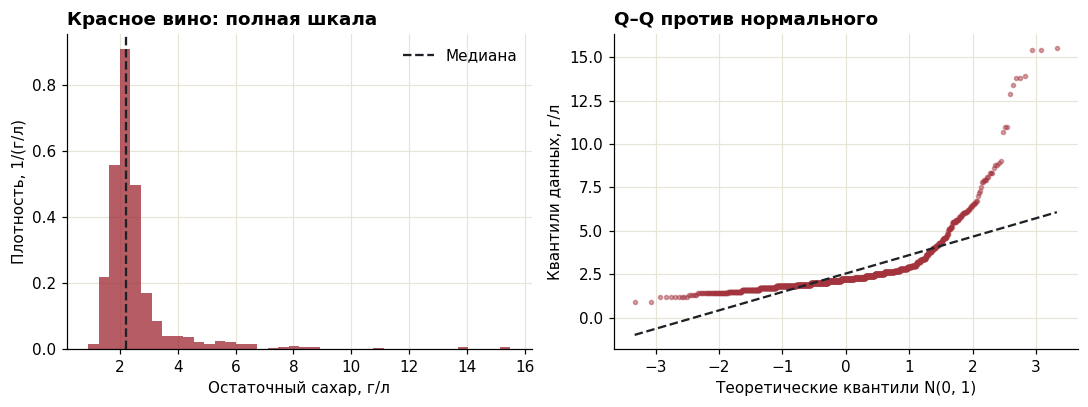

In [4]:
display(a['red_stats'].loc[['Остаточный сахар']].T)
display(extra_plot_eda(a['red'],'residual sugar'))


**Что показывают данные.** Среднее — **2.5388 г/л**, медиана — **2.20 г/л**, стандартное отклонение — **1.4099 г/л**. Центральные 50% наблюдений лежат между **1.90 и 2.60 г/л**; полный диапазон — от 0.90 до 15.50 г/л.

**Форма и крайние значения.** Асимметрия 4.541, эксцесс 28.618; за границами 1.5·IQR — 155 строк (9.7%). Редкие высокие значения сильно влияют на среднее и особенно на асимметрию. Поэтому для типичного образца дополнительно используем медиану и межквартильный интервал. Большая доля выбросов по узкому IQR не означает, что все эти измерения ошибочны.

**Нормальность.** Шапиро — Уилк: W=0.5661, p=1.02e-52. При α=0.05 нормальность отвергается; форму проверяем также по гистограмме и Q–Q. Выбросы остаются в расчётах: правило IQR выявляет крайние значения, но само по себе не доказывает ошибку измерения.


<a id="extra-alcohol"></a>
## 7.3 Содержание спирта · Красное вино

### Description


**Величина Y — объёмная доля спирта, % об.** Один процентный пункт соответствует изменению,
например, с 10 до 11 % об. Поэтому среднее указываем в % об., а стандартное отклонение и разность
средних — в процентных пунктах.

Для случайно выбранного красного вина неизвестны начальное количество сахара, активность дрожжей,
длительность и условия брожения. Измерение также имеет погрешность. Теоретическая схема превращения
сахара в этанол не задаёт точную долю спирта без этих условий и исходного состава.

Формально Y(ω) — значение `alcohol` случайно выбранной строки ω. До выбора образца значение
неизвестно: Y — случайная величина. Физическая доля непрерывна, но измерения округлены.
Поскольку X и Y относятся к одним винам, их зависимость нужно исследовать, а не предполагать заранее.


### EDA & Distribution


Величина,Содержание спирта
n,1599
Среднее,10.423
Медиана,10.2
Std,1.06567
Min,8.4
Q1,9.5
Q3,11.1
Max,14.9
Асимметрия,0.860829
Эксцесс,0.200029


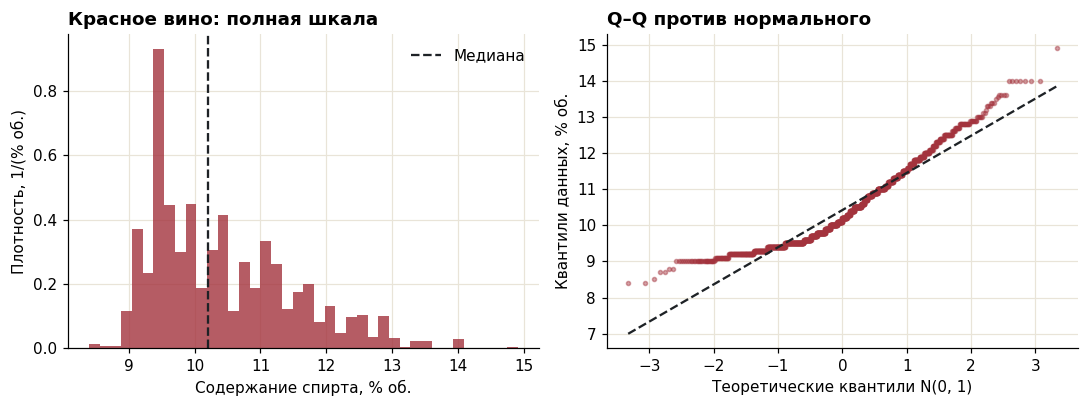

In [5]:
display(a['red_stats'].loc[['Содержание спирта']].T)
display(extra_plot_eda(a['red'],'alcohol'))


**Что показывают данные.** Среднее — **10.4230 % об.**, медиана — **10.20 % об.**, стандартное отклонение — **1.0657 процентного пункта**. Центральные 50% наблюдений лежат между **9.50 и 11.10 % об.**; полный диапазон — от 8.40 до 14.90 % об..

**Форма и крайние значения.** Асимметрия 0.861, эксцесс 0.200; за границами 1.5·IQR — 13 строк (0.8%). Среднее выше медианы; правый хвост длиннее левого. Повторяющиеся значения и пики согласуются с округлением записей и неоднородностью образцов. Это непрерывная физическая величина, хотя измерения записаны с конечной точностью.

**Нормальность.** Шапиро — Уилк: W=0.9288, p=6.64e-27. При α=0.05 нормальность отвергается; форму проверяем также по гистограмме и Q–Q. Выбросы остаются в расчётах: правило IQR выявляет крайние значения, но само по себе не доказывает ошибку измерения.


<a id="extra-dependence"></a>
## 7.4 Independence · Зависимость сахара и спирта


**Зависимость.** Основной показатель — корреляция Спирмена (монотонная связь рангов),
дополнительно считаем Пирсона (линейная связь) и χ² для квантильных групп.
Для χ² H₀: группы сахара и спирта независимы; H₁: зависимы.
Квантильные границы рассчитываются отдельно внутри каждого типа вина; совпавшие значения не разрываем.
Разбиение получается приблизительно равным по числу строк, поскольку наблюдения округлены.
Неотвержение гипотезы о нулевой корреляции не является доказательством независимости.

**Сравнение двух типов.** Используем двусторонний Манн — Уитни с поправкой на совпадающие ранги.
Объёмы различаются, поэтому для графиков используем плотности, а не абсолютные частоты,
и одинаковые границы столбиков. На диаграммах рассеяния обе оси имеют общие пределы.
Графики строятся по исходным значениям: раздельная стандартизация групп скрыла бы различия центра и масштаба.

**Размер эффекта.** U относится к красной группе; знак коэффициента показывает направление:
отрицательный — значения красного вина чаще ниже. Ноль не означает совпадение распределений.

$$A=\frac{U_R}{n_Rn_W}=P(X_R>X_W)+\tfrac12P(X_R=X_W),\qquad r_{rb}=2A-1.$$

**Две проверки, а не два шанса найти значимость.** Для сравнений сахара и спирта применяем
поправку Холма: сортируем два p-value, умножаем их на 2 и 1 соответственно,
обеспечиваем неубывание и ограничиваем результат единицей. Сравниваем скорректированные p с α=0.05.
Проверки зависимости внутри красного вина — отдельный исследовательский блок;
основной показатель задан заранее, дополнительные тесты служат проверкой картины связи.


,Красное,Белое
n,1599,4898
Пирсон r,0.0420754,-0.450631
Пирсон p,0.0925842,1.20621e-243
Спирмен ρ,0.116548,-0.445257
Спирмен p,2.97185e-06,3.08943e-237
χ²,33.8656,1355.52
χ² p,9.4297e-05,3.15153e-286
df,9,9
V Крамера,0.0840224,0.303726
min ожидаемая частота,83.6992,280.622


alcohol,"(8.399000000000001, 9.5]","(9.5, 10.2]","(10.2, 11.1]","(11.1, 14.9]"
residual sugar,,,,
"(0.899, 1.9]",154,119,105,86
"(1.9, 2.2]",107,130,82,100
"(2.2, 2.6]",84,85,100,92
"(2.6, 15.5]",91,72,90,102


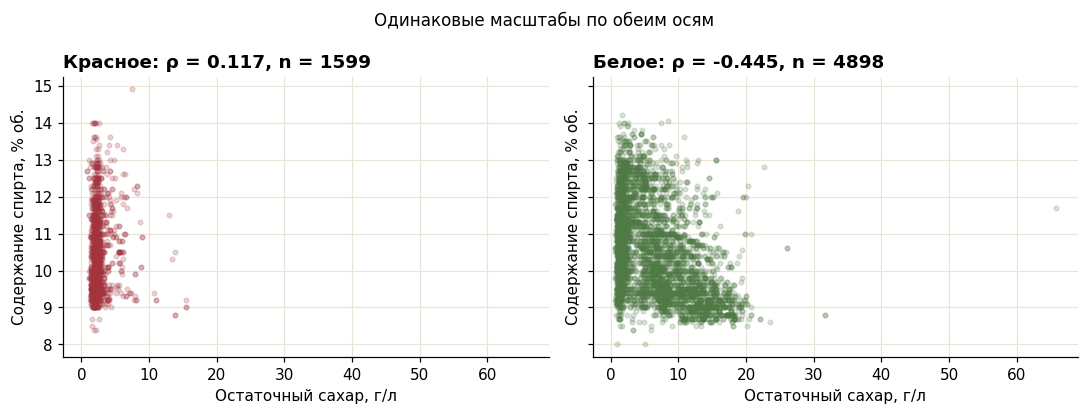

In [6]:
dependence=pd.DataFrame({
    name:{k:v for k,v in values.items() if k!='table'}
    for name,values in [('Красное',a['red_dep']),('Белое',a['white_dep'])]
})
display(dependence)
display(a['red_dep']['table'])
display(extra_plot_pairs(a))


**У красного вина слабая связь, а не доказанная независимость.** Пирсон: r=0.0421, p=0.0926; Спирмен: ρ=0.1165, p=2.97e-06. Пирсон оценивает линейную связь, Спирмен — монотонную связь рангов. Большое p у одного коэффициента не доказывает независимость.

**Проверка через таблицу сопряжённости.** χ²=33.866, df=9, p=9.43e-05; V Крамера=0.084. Минимальная ожидаемая частота 83.70, то есть больше 5. Нулевая гипотеза независимости сгруппированных величин отвергается, но размер связи мал. Границы групп и V зависят от способа разбиения; это дополнительная проверка к основному ранговому анализу.

**Сравнение связей.** У белого вина ρ=-0.4453, у красного — 0.1165. В этих данных выраженная отрицательная связь белого вина не воспроизводится у красного. Химическая схема брожения сама по себе не определяет межобразцовую корреляцию: неизвестны исходный сахар, технология и другие условия. Сравнение коэффициентов описательное; отдельный формальный тест равенства корреляций здесь не проводился.


<a id="extra-comparison"></a>
## 7.5 Сравнение красного и белого вина

Границы столбиков общие, высоты показывают плотность. ECDF показывает долю значений ≤ x. В интерактивной версии сайта можно менять показатель, число столбиков, область отображения и режим обработки повторов. Здесь сохранён основной анализ всех строк на полных шкалах.


Величина,Остаточный сахар,Содержание спирта
n красное,1599,1599
n белое,4898,4898
Среднее красное,2.53881,10.423
Среднее белое,6.39141,10.5143
Медиана красное,2.2,10.2
Медиана белое,5.2,10.4
Δ средних: красное − белое,-3.85261,-0.0912839
U,2.56969e+06,3.82904e+06
p,5.63407e-95,0.181845
r_rb,-0.34379,-0.0221932


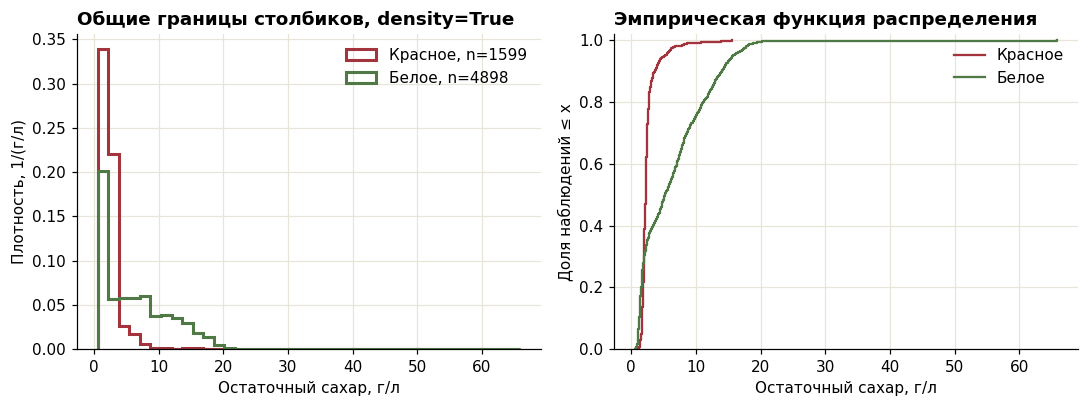

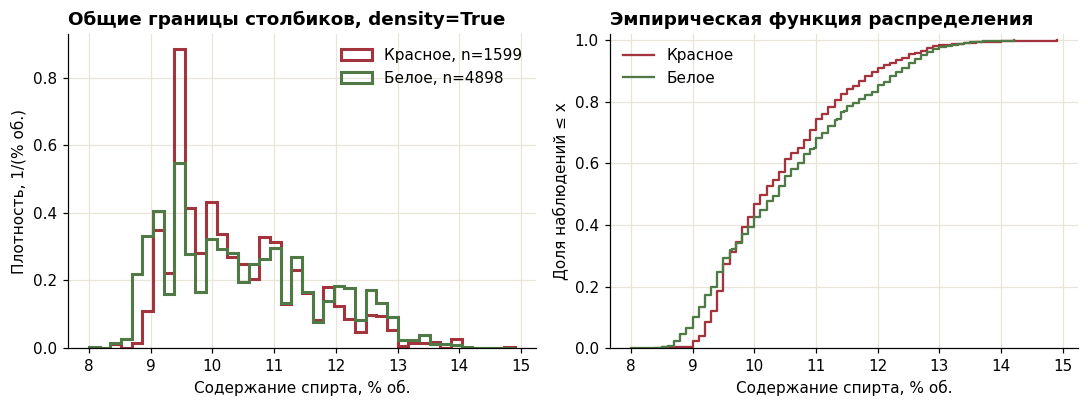

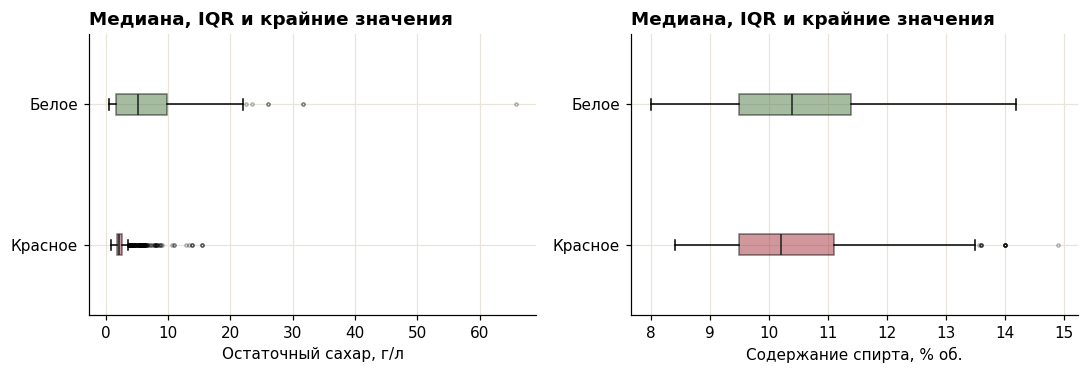

In [7]:
display(a['comparison'].T)
display(extra_plot_comparison(a,'residual sugar',40,False))
display(extra_plot_comparison(a,'alcohol',40,False))
display(extra_plot_box(a))


**Сахар: различие заметно.** Медианы красного и белого вина — **2.20 и 5.20 г/л**; p Holm=1.13e-94, r_rb=-0.344. В красном наборе концентрации чаще ниже. При этом распределения перекрываются, и по одному сахару нельзя безошибочно определить тип вина.

**Спирт: различие гораздо меньше.** Медианы — **10.20 и 10.40 % об.**, разность средних (красное − белое) **-0.0913 процентного пункта**; p Holm=0.182, r_rb=-0.022. Для распределений спирта нет оснований отвергнуть H₀ после поправки Холма; это не доказательство равенства. Смотрите на малую величину эффекта вместе с p-value.

**Что именно проверяется.** Для каждой величины H₀: распределения в двух группах одинаковы; H₁: различаются. Двусторонний критерий Манна — Уитни использует ранги и поправку на совпадающие значения. Это не отдельный тест равенства средних или медиан при произвольной форме распределений. Поправка Холма применяется к двум сравнениям красного и белого вина (сахар и спирт), семейный α=0.05. Тест чувствителен к ранговым сдвигам и не обнаруживает все возможные различия формы.


<a id="extra-sensitivity"></a>
## 7.6 Устойчивость к обработке полных повторов


In [8]:
display(extra_sensitivity(red_raw,white_raw))


n красное  n белое        p Holm      r_rb          Решение
Режим               Величина                                                                      
Все строки          Остаточный сахар        1599     4898  1.126815e-94 -0.343790     Отвергаем H₀
                    Содержание спирта       1599     4898  1.818451e-01 -0.022193  Не отвергаем H₀
Без полных повторов Остаточный сахар        1359     3961  1.735966e-57 -0.290805     Отвергаем H₀
                    Содержание спирта       1359     3961  2.596886e-04 -0.066273     Отвергаем H₀

**Почему проверяем повторы отдельно.** При сохранении всех строк по сахару различие выражено,
а по спирту Манн — Уитни не отвергает H₀. После удаления полных повторов различие по спирту
становится статистически значимым, но ранговый эффект остаётся небольшим (|r_rb| примерно 0.066).
Для сахара направление и значимость различия сохраняются.

Значит, вывод «спирт одинаковый» был бы неверным. Более аккуратно: **распределения спирта сильно
перекрываются, ранговый эффект мал, а решение теста чувствительно к обработке повторов**.
По сахару вывод устойчивее. Удаление повторов меняет веса наблюдений и не восстанавливает
неизвестную структуру партий; оно не решает автоматически проблему независимости измерений.
К каждому режиму применяется одна и та же процедура: две проверки и поправка Холма.

Выбросы IQR не удалялись ни в одном режиме. При включении увеличения на графике меняются только
пределы оси: крайние значения остаются в статистиках и тестах.


<a id="extra-resume"></a>
## 7.7 Lab resume


**Что выполнено.** Для красного вина исследованы две случайные величины: остаточный сахар и
содержание спирта. Для каждой объяснён случайный эксперимент, выполнены EDA, оценка формы и
проверка нормальности. Значения за границами IQR сохранены, потому что крайнее значение не равно ошибке.

**Что узнали о красном вине.** Сахар сосредоточен в узкой области, но редкие высокие значения
создают сильный правый хвост. Спирт имеет более умеренную правую асимметрию. Обе величины не описываются
точно нормальным законом. Зависимость между ними слабая; считать их строго независимыми оснований нет.

**Зачем сравнивали с белым.** В исходных таблицах у красного вина ниже типичный сахар:
медиана 2.2 против 5.2 г/л. По спирту различия намного меньше: медианы 10.2 и 10.4 % об.
Отрицательная связь сахара и спирта у белых вин не воспроизводится у красных с той же силой.
Это показывает, почему результаты одного набора нельзя автоматически переносить на другой.

**Насколько выводы надёжны.** По сахару направление сравнения сохраняется после удаления
полных повторов. По спирту меняется формальное решение теста, а размер рангового эффекта остаётся малым.
Поэтому указываем и p-value, и размер эффекта, и чувствительность к подготовке данных.
Выводы относятся к имеющимся образцам Vinho Verde, а не ко всем красным и белым винам.

**Граница этапа.** Генератор, интерактивный генератор, его тесты и второй спринт инфохимиков
здесь не реализованы и не заявлены. Интерактивность этого раздела относится только к исследованию данных.


<a id="extra-criteria"></a>
### 7.8 cat_mark_table


| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| Доп. КТиД: отдельный датасет | [7.1](#extra-data) | 1 | winequality-red.csv: отдельный файл и другие образцы той же коллекции UCI |
| Две случайные величины | [7.2](#extra-sugar) · [7.3](#extra-alcohol) | 1 | остаточный сахар, г/л; спирт, % об. |
| Обоснование случайности | [7.2](#extra-sugar) · [7.3](#extra-alcohol) | 1 | случайный выбор образца, неизвестные условия, погрешности измерений |
| Исследование зависимости | [7.4](#extra-dependence) | 1 | Пирсон, Спирмен, χ², V Крамера; отсутствие корреляции не приравнивается к независимости |
| EDA | [7.2](#extra-sugar) · [7.3](#extra-alcohol) | 1 | статистики, выбросы IQR, гистограммы, Q–Q, нормальность |
| Сравнение с белым вином | [7.5](#extra-comparison) | — | дополнительное развитие: общие шкалы, плотности, ECDF, Манн — Уитни, эффект и поправка Холма |
| Проверка устойчивости | [7.6](#extra-sensitivity) | — | основной анализ и удаление полных повторов; ограничения интерпретации |
| Оформление КТиД | [7](#extra) | 1 | номера, якоря, скрытый код, единицы, единая стилистика, LaTeX |
| Использование marimo | [7.5](#extra-comparison) | 1 | интерактивный выбор величины, числа столбиков и масштаба |
| Интерактивность генератора | — | — | отложено до работы инфохимиков; генератора пока нет |


<a id="extra-refs"></a>
### 7.9 Источники


1. Cortez P. et al. Wine Quality. UCI Machine Learning Repository, 2009.
   [Карточка и файлы данных](https://archive.ics.uci.edu/dataset/186/wine+quality),
   DOI: [10.24432/C56S3T](https://doi.org/10.24432/C56S3T).
   В расчётах использованы комплектные winequality-red.csv и winequality-white.csv;
   сведения об источнике сверены с winequality.names.
2. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining
   from physicochemical properties. Decision Support Systems, 47(4), 2009, 547–553.
   [DOI: 10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016).
   Это публикация происхождения данных; её результаты не использовались вместо собственного анализа.
3. SciPy. [mannwhitneyu](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html):
   проверяемая гипотеза, ранги и совпадающие значения.
4. SciPy. [chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.chi2_contingency.html):
   критерий независимости и ожидаемые частоты.
5. SciPy. [spearmanr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html),
   [pearsonr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html),
   [shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html).
